In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib
import sklearn

In [2]:
# Set the directory in which to store data
NB_DIR = Path.cwd()       # Set NB_DIR to be the current working directory
DATA = NB_DIR/'data'      # The data dir is the subdirectory 'data' under NB_DIR

In [3]:
#Definer sti til processed-mappen (data/processed) for eventuelle prosseserte datafiler
PROCESSED_DATA = DATA / "processed"

# Opprett 'processed'-mappen dersom den ikke finnes fra før
PROCESSED_DATA.mkdir(parents=True, exist_ok=True)

In [4]:
import urllib.request

# Define the file path
FILE = DATA / 'World-Stock-Prices-Dataset.csv'

In [5]:
#Leser inn data fra CSV-filen og viser de første radene i datasettet for å få en oversikt over strukturen og innholdet.
stockdata = pd.read_csv(FILE)

stockdata.head()

,Date,Open,High,Low,Close,Volume,Brand_Name,Ticker,Industry_Tag,Country,Dividends,Stock Splits,Capital Gains
0,2025-07-03 00:00:00-04:00,6.630000,6.740000,6.615000,6.640000,4209664.0,peloton,PTON,fitness,usa,0.0,0.0,NaN
1,2025-07-03 00:00:00-04:00,106.750000,108.370003,106.330101,107.339996,560190.0,crocs,CROX,footwear,usa,0.0,0.0,NaN
2,2025-07-03 00:00:00-04:00,122.629997,123.050003,121.550003,121.930000,36600.0,adidas,ADDYY,apparel,germany,0.0,0.0,NaN
3,2025-07-03 00:00:00-04:00,221.705002,224.009995,221.360001,223.410004,29295154.0,amazon,AMZN,e-commerce,usa,0.0,0.0,NaN
4,2025-07-03 00:00:00-04:00,212.145004,214.649994,211.810104,213.550003,34697317.0,apple,AAPL,technology,usa,0.0,0.0,NaN


In [6]:
#De 5 radene fra .head() har samme dato, undersøker historikken for å se hvor langt tilbake dataene går.
print("Antall rader:", len(stockdata))
print("Antall selskaper:", stockdata["Ticker"].nunique())
print("Antall unike datoer:", stockdata["Date"].nunique())

print("Første dato:", stockdata["Date"].min())
print("Siste dato:", stockdata["Date"].max())

print(stockdata.groupby("Ticker").size().describe())

Antall rader: 310122
Antall selskaper: 62
Antall unike datoer: 6408
Første dato: 2000-01-03 00:00:00-05:00
Siste dato: 2025-07-03 00:00:00-04:00
count      62.000000
mean     5001.967742
std      1976.081003
min         1.000000
25%      3938.500000
50%      6469.000000
75%      6470.000000
max      6471.000000
dtype: float64


In [7]:
#Har datasettet mangler? Vi sjekker for duplikater og manglende verdier
print(stockdata.isnull().sum().sort_values(ascending=False))

print("Antall dupliserte rader:", stockdata.duplicated().sum())

print("Duplikater per aksje og dato:",
      stockdata.duplicated(subset=["Ticker", "Date"]).sum())

Capital Gains    310120
Date                  0
Open                  0
High                  0
Low                   0
Close                 0
Volume                0
Brand_Name            0
Ticker                0
Industry_Tag          0
Country               0
Dividends             0
Stock Splits          0
dtype: int64
Antall dupliserte rader: 0
Duplikater per aksje og dato: 3677


In [8]:
#Capital Gains mangler i nesten alle radene, og 3677 rader har samme kombinasjon av Ticker og Date. 
#Neste steg er å undersøke disse duplikatene for å finne ut om de er reelle dobbeltregistreringer eller feil i datasettet.
duplicates = stockdata[stockdata.duplicated(subset=["Ticker", "Date"], keep=False)]

print(duplicates.sort_values(["Ticker", "Date"]).head(10))

                            Date        Open        High         Low  \
30910  2023-09-08 00:00:00-04:00  178.350006  180.238998  177.789993   
31010  2023-09-08 00:00:00-04:00  178.350006  180.240005  177.789993   
30746  2023-09-13 00:00:00-04:00  176.509995  177.300003  173.979996   
30823  2023-09-13 00:00:00-04:00  176.509995  177.300003  173.979996   
30569  2023-09-15 00:00:00-04:00  176.479996  176.500000  173.820007   
30623  2023-09-15 00:00:00-04:00  176.479996  176.494995  173.820007   
19032  2024-06-14 00:00:00-04:00  213.850006  215.169998  211.300003   
19099  2024-06-14 00:00:00-04:00  213.809998  215.169998  211.300003   
18755  2024-06-21 00:00:00-04:00  210.389999  211.889999  207.110001   
18839  2024-06-21 00:00:00-04:00  210.389999  211.889999  207.110001   

            Close       Volume Brand_Name Ticker Industry_Tag Country  \
30910  178.179993   65602066.0      apple   AAPL   technology     usa   
31010  178.179993   65551300.0      apple   AAPL   technology

*** Her ser vi faktisk at at Apple(AAPL) har på 2023-09-08 registrert 2 stk colonner med data. "Open" er helt lik mens high er forskjellige. Dette er litt rart hvis "high" skal være dagens høyeste pris, da de også har samme "low". ***

In [9]:
#Vi sjekker da om det er noen selskaper som har flere duplikater enn andre, og hvor mange aksje-datoer som er berørt.
duplicates = stockdata[stockdata.duplicated(subset=["Ticker", "Date"], keep=False)]

print("Antall ekstra registreringer:",
      stockdata.duplicated(subset=["Ticker", "Date"]).sum())

print("Antall berørte aksje-datoer:",
      duplicates.groupby(["Ticker", "Date"]).ngroups)

print("Antall berørte selskaper:",
      duplicates["Ticker"].nunique())

Antall ekstra registreringer: 3677
Antall berørte aksje-datoer: 3677
Antall berørte selskaper: 61


In [10]:
#Vi sjekker om rader med samme Ticker(ID) og Date har forskjellige verdier for pris og volum.
duplicates = stockdata[stockdata.duplicated(subset=["Ticker", "Date"], keep=False)]

print(
    duplicates.groupby(["Ticker", "Date"])[
        ["Open", "High", "Low", "Close", "Volume"]
    ].nunique().gt(1).sum()
)

Open      1041
High      1394
Low       1386
Close       45
Volume    3665
dtype: int64


*** Dette viser at duplikatene ofte har ulike verdier, særlig for Volume (3665 grupper) og High (1394 grupper), så vi kan ikke trygt behandle dem som identiske rader. Konkluderer med at det er mer relevant å slette kolonnen "Capital Gains" da den er tom på 310120 av 310122 (altså bare 2 stk som er fylt ut). ***

In [11]:
stockdata = stockdata.drop(columns=["Capital Gains"])

In [12]:
stockdata.head()

,Date,Open,High,Low,Close,Volume,Brand_Name,Ticker,Industry_Tag,Country,Dividends,Stock Splits
0,2025-07-03 00:00:00-04:00,6.630000,6.740000,6.615000,6.640000,4209664.0,peloton,PTON,fitness,usa,0.0,0.0
1,2025-07-03 00:00:00-04:00,106.750000,108.370003,106.330101,107.339996,560190.0,crocs,CROX,footwear,usa,0.0,0.0
2,2025-07-03 00:00:00-04:00,122.629997,123.050003,121.550003,121.930000,36600.0,adidas,ADDYY,apparel,germany,0.0,0.0
3,2025-07-03 00:00:00-04:00,221.705002,224.009995,221.360001,223.410004,29295154.0,amazon,AMZN,e-commerce,usa,0.0,0.0
4,2025-07-03 00:00:00-04:00,212.145004,214.649994,211.810104,213.550003,34697317.0,apple,AAPL,technology,usa,0.0,0.0


*** Forønyd med datanalysen for øyeblikket. ***
*** Lager en visuell representasjon for hvordan en aksje beveger seg i løpet av et år. ***

In [13]:
#Fikk feil på dato, så vi konverterer til datetime med UTC for å unngå problemer med tidssoner.
stockdata["Date"] = pd.to_datetime(stockdata["Date"], utc=True)

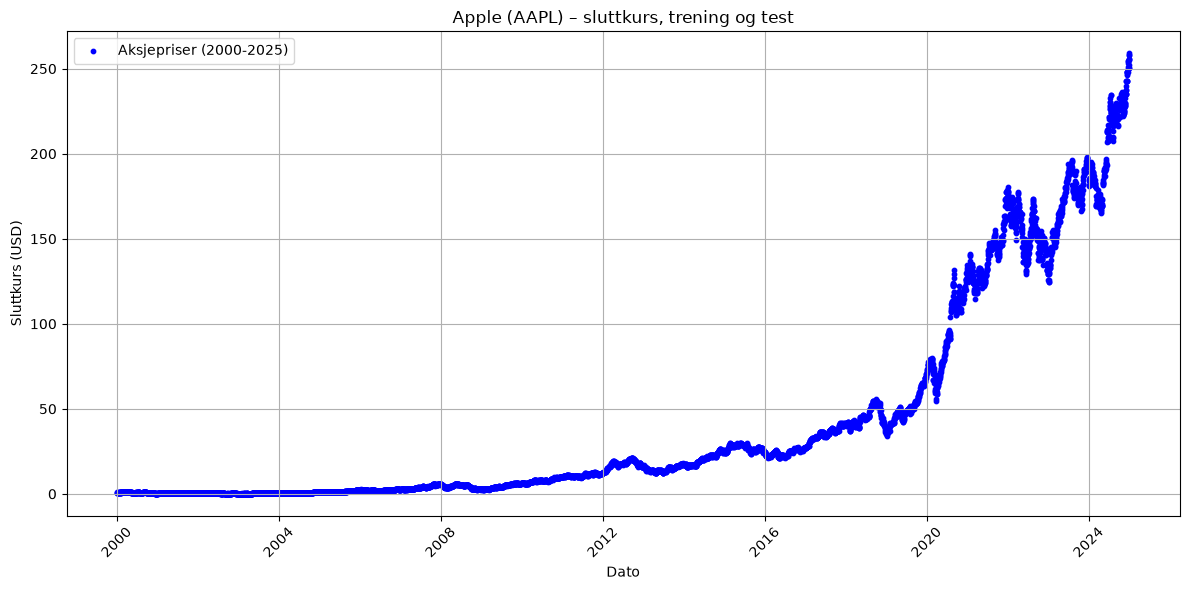

In [14]:
#Visualsering av Apple-aksjen (AAPL) for å se på sluttkursen over tid. Vi velger å se på data fra 2000 til 2025.
siste_dato = stockdata["Date"].max()
start_dato = siste_dato - pd.DateOffset(years=1)

apple = stockdata[stockdata["Ticker"] == "AAPL"].copy()

data = apple[
    (apple["Date"] >= "2000-01-01") &
    (apple["Date"] < "2025-01-01")
]

plt.figure(figsize=(12, 6))

plt.scatter(data["Date"], data["Close"], s=10, label="Aksjepriser (2000-2025)", color="blue")

plt.title("Apple (AAPL) – sluttkurs, trening og test")
plt.xlabel("Dato")
plt.ylabel("Sluttkurs (USD)")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

*** Her ser vi hvordan aksjen sin "Close" pris endrer seg fra 2000-2025. Vi kan se tydelig at den har jevnt over hatt en stigende trend, med en markant stigning etter 2020.***

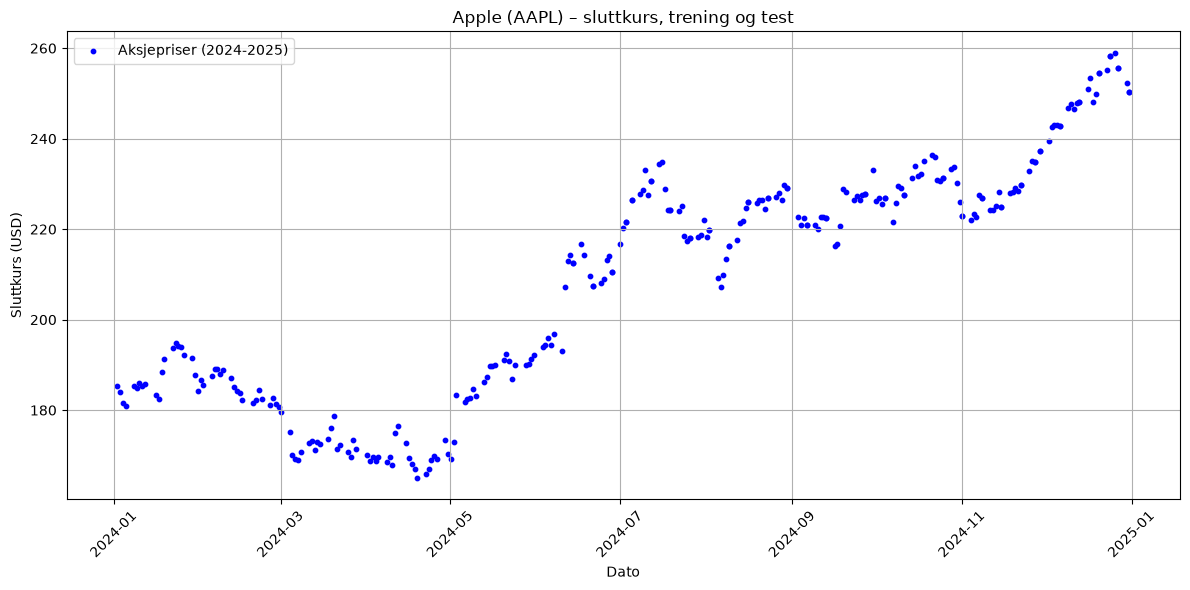

In [15]:
#Ser vi på dataen fra 2024 til 2025, kan vi se at det er en del variasjon i sluttkursen for Apple-aksjen. 
#Dette kan være nyttig for å analysere trender og mønstre i aksjeprisen over kortere intervaller.
siste_dato = stockdata["Date"].max()
start_dato = siste_dato - pd.DateOffset(years=1)

apple = stockdata[stockdata["Ticker"] == "AAPL"].copy()

# Data: 2024-2025
data = apple[
    (apple["Date"] >= "2024-01-01") &
    (apple["Date"] < "2025-01-01")
]

plt.figure(figsize=(12, 6))

plt.scatter(data["Date"], data["Close"], s=10, label="Aksjepriser (2024-2025)", color="blue")

plt.title("Apple (AAPL) – sluttkurs, trening og test")
plt.xlabel("Dato")
plt.ylabel("Sluttkurs (USD)")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [16]:
#Vi undersøker om det er noen bransjer som har hatt spesielt høy eller lav prosentvis endring i aksjekursen over tid,
#og om det er noen trender som kan identifiseres.

#Sorter etter aksje og dato
df = stockdata.sort_values(["Ticker", "Date"])

# Første og siste sluttkurs per aksje
aksjer = df.groupby(["Ticker", "Brand_Name", "Industry_Tag"]).agg(
    første_kurs=("Close", "first"),
    siste_kurs=("Close", "last"),
    første_dato=("Date", "min"),
    siste_dato=("Date", "max")
)

# Prosentvis kursendring
aksjer["prosent_endring"] = (
    (aksjer["siste_kurs"] - aksjer["første_kurs"])
    / aksjer["første_kurs"] * 100
)

print(aksjer.sort_values("prosent_endring", ascending=False))

# Gjennomsnittlig prosentvis endring per bransje
bransjer = aksjer.groupby("Industry_Tag")["prosent_endring"].mean()

print(bransjer.sort_values(ascending=False))

                                 første_kurs   siste_kurs  \
Ticker Brand_Name Industry_Tag                              
NFLX   netflix    entertainment     1.196429  1297.180054   
AAPL   apple      technology        0.848323   213.550003   
TSLA   tesla      automotive        1.592667   315.350006   
NVDA   nvidia     technology        0.894729   159.339996   
MA     mastercard finance           4.234622   569.239990   
...                                      ...          ...   
TWTR   twitter    social media     53.700001    53.700001   
ABNB   airbnb     hospitality     144.710007   136.490005   
UBSFY  ubisoft    gaming            2.683385     2.090000   
ZI     zoominfo   technology       34.000000    10.260000   
PTON   peloton    fitness          25.760000     6.640000   

                                              første_dato  \
Ticker Brand_Name Industry_Tag                              
NFLX   netflix    entertainment 2002-05-23 04:00:00+00:00   
AAPL   apple      techn

*** Her ser vi at det er veldig høye stigninger på noen aksjer, over 100.000 % økning. Det kan være misvisende da Netflix f.eks har hatt aksjesplitter og datasettet er kanskje ikke justert for dette. Vi velger da å ikke gå dypere i dette. ***
*** Det ser ut til at 5 kategorier har gjort det veldig bra i askje-verden siden 2000 med høy prosent stigning: ***

entertainment         54378.710801
e-commerce             5826.750977
technology             4920.974157
finance                4520.593481
automotive             4070.268245

*** Dataene vi har analysert ser ut til å være linjær med datoer og priser som varierer over tid. ***
*** Derfor velger vi da å begynne med en regressjonsmodell som kan fange opp lineære trender i dataene, ***
*** hvor vi kan predikere om aksjekursen vil stige eller falle basert på historiske data. ***

In [19]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

#Tester en Logistic Regression-modell for å predikere om Apple-aksjen vil stige eller falle basert på historiske data.
#Sjekker resultater og evaluerer modellen med accuracy, f1-score og confusion matrix.

apple = stockdata[stockdata["Ticker"] == "AAPL"].copy()
apple = apple.sort_values("Date")

#Lager målvariabel: 1 hvis neste sluttkurs er høyere
apple["Next_Close"] = apple["Close"].shift(-1)
apple["Target"] = (apple["Next_Close"] > apple["Close"]).astype(int)

# Fjern siste rad, som ikke har en kjent neste sluttkurs
apple = apple.dropna(subset=["Next_Close"])

#Velger inputvariabler
features = ["Open", "High", "Low", "Close", "Volume"]
X = apple[features]
y = apple["Target"]

#Del i trening (2023) og test (2024)
train_mask = (
    (apple["Date"] >= "2023-01-01") &
    (apple["Date"] < "2024-01-01")
)
test_mask = (
    (apple["Date"] >= "2024-01-01") &
    (apple["Date"] < "2025-01-01")
)

X_train, y_train = X[train_mask], y[train_mask]
X_test, y_test = X[test_mask], y[test_mask]

#Tren modellen
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)
model.fit(X_train, y_train)

#Evaluer modellen
y_pred = model.predict(X_test)

print("Antall treningsrader:", len(X_train))
print("Antall testrader:", len(X_test))
print("Accuracy:", accuracy_score(y_test, y_pred))
print("F1-score:", f1_score(y_test, y_pred, zero_division=0))
print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred, zero_division=0))

Antall treningsrader: 252
Antall testrader: 283
Accuracy: 0.4840989399293286
F1-score: 0.32407407407407407
Confusion matrix:
[[102  39]
 [107  35]]
              precision    recall  f1-score   support

           0       0.49      0.72      0.58       141
           1       0.47      0.25      0.32       142

    accuracy                           0.48       283
   macro avg       0.48      0.48      0.45       283
weighted avg       0.48      0.48      0.45       283



# DummyClassifier
*** Vi lager en DummyClassifier for å ha en baseline å sammenligne algortimer mot. ***

In [20]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score

#Bruk DummyClassifier som baseline; den predikerer alltid den vanligste klassen i treningsdataene og 
# gir deg et sammenligningsgrunnlag for andre modeller.

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

y_baseline = baseline.predict(X_test)

print("Baseline accuracy:", accuracy_score(y_test, y_baseline))
print("Baseline F1-score:", f1_score(y_test, y_baseline, zero_division=0))

Baseline accuracy: 0.5017667844522968
Baseline F1-score: 0.668235294117647


#Baseline
*** Baseline får høy F1-score fordi den alltid predikerer den vanligste klassen, som i dette datasett ser ut til å være oppgang. Det er likevel viktig å tolke F1 sammen med accuracy og confusion matrix, når man sammenligner den mot andre modeller. Baseline klarer ikke klarer å skille mellom dager med oppgang og nedgang f.eks. ***

*** Baseline-modellen oppnår 50,18 % accuracy, mot Logistic Regression sine 48,41 %. Det betyr at Logistic Regression presterer dårligere enn å alltid velge den vanligste klassen. Vi velger derfor å teste med Decision Tree på de samme trenings og testdataene. ***

In [21]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score

tree = DecisionTreeClassifier(max_depth=3, random_state=42)
tree.fit(X_train, y_train)

y_tree = tree.predict(X_test)

print("Decision Tree accuracy:", accuracy_score(y_test, y_tree))
print("Decision Tree F1-score:", f1_score(y_test, y_tree, zero_division=0))

Decision Tree accuracy: 0.5017667844522968
Decision Tree F1-score: 0.4426877470355731


*** Decision Tree oppnår samme accuracy som baseline (50,18 %), men lavere F1-score enn baseline (0,44 mot 0,67). ***
Vi prøver med RandomForrestClassifier:

In [22]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

forest = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    random_state=42
)

forest.fit(X_train, y_train)
y_forest = forest.predict(X_test)

print("Random Forest accuracy:", accuracy_score(y_test, y_forest))
print("Random Forest F1-score:", f1_score(y_test, y_forest, zero_division=0))

Random Forest accuracy: 0.49823321554770317
Random Forest F1-score: 0.3879310344827586


# Samlet sammenligning:

In [23]:
results = pd.DataFrame({
    "Modell": [
        "Baseline",
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_baseline),
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, y_tree),
        accuracy_score(y_test, y_forest)
    ],
    "F1-score": [
        f1_score(y_test, y_baseline, zero_division=0),
        f1_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, y_tree, zero_division=0),
        f1_score(y_test, y_forest, zero_division=0)
    ]
})

print(results.sort_values("Accuracy", ascending=False).round(3))

                Modell  Accuracy  F1-score
0             Baseline     0.502     0.668
2        Decision Tree     0.502     0.443
3        Random Forest     0.498     0.388
1  Logistic Regression     0.484     0.324


 *** Resultatene viser at ingen av de tre maskinlæringsmodellene slår baseline.. Neste steg kan være å undersøke om målvariabelen er balansert i treningsdataene, ved å telle hvor mange dager som har oppgang (1) og nedgang (0). Dette hjelper oss å forstå hvorfor baseline gjør det såpass bra. ***

In [40]:
print(y_train.value_counts())
print((y_train.value_counts(normalize=True) * 100).round(2))

Target
1    140
0    112
Name: count, dtype: int64
Target
1    55.56
0    44.44
Name: proportion, dtype: float64


*** Treningsdataene har en relativt balansert fordeling: 55,56 % oppgang og 44,44 % nedgang, så klasseubalanse alene forklarer neppe de svake resultatene. ***
*** Kan vi prøve å optimalisere Random Forrest med å kjøre GridSearchCV for å finne bedre parametere? ***

In [24]:
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(random_state=42))
])

param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [3, 5, 10, None],
    "model__min_samples_leaf": [2, 5, 10],
    "model__max_features": ["sqrt", 0.8]
}

tscv = TimeSeriesSplit(n_splits=3)

grid = GridSearchCV(
    pipeline,
    param_grid,
    cv=tscv,
    scoring="f1",
    n_jobs=-1
)

grid.fit(X_train, y_train)

print("Beste parametere:", grid.best_params_)
print("Beste F1-score i kryssvalidering:", round(grid.best_score_, 3))

Beste parametere: {'model__max_depth': 3, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 2, 'model__n_estimators': 200}
Beste F1-score i kryssvalidering: 0.661


In [25]:
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

best_model = grid.best_estimator_

y_pred_tuned = best_model.predict(X_test)

print("Test accuracy:", accuracy_score(y_test, y_pred_tuned))
print("Test F1-score:", f1_score(y_test, y_pred_tuned, zero_division=0))
print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred_tuned))

Test accuracy: 0.5053003533568905
Test F1-score: 0.4117647058823529
Confusion matrix:
[[94 47]
 [93 49]]


*** Resultatet viser at optimaliseringen ga 50,53 % accuracy på testdataene, men F1-score på 0,412. Modellen finner bare 49 av 142 faktiske oppgangsdager, så prediksjonsevnen er fortsatt svak. ***

*** Beregn precision og recall for Target = 1 for den optimaliserte modellen, slik at vi kan vurdere om den faktisk er nyttig til å forutsi oppgang. ***

In [26]:
from sklearn.metrics import precision_score, recall_score

print("Precision:", precision_score(y_test, y_pred_tuned, zero_division=0))
print("Recall:", recall_score(y_test, y_pred_tuned, zero_division=0))

Precision: 0.5104166666666666
Recall: 0.34507042253521125


*** Sammenlign disse metrikken med baseline-modellen ved å beregne precision og recall for y_baseline, slik at vi ser om optimaliseringen gir en reell forbedring. ***

In [28]:
print("Baseline precision:", precision_score(y_test, y_baseline, zero_division=0))
print("Baseline recall:", recall_score(y_test, y_baseline, zero_division=0))

Baseline precision: 0.5017667844522968
Baseline recall: 1.0


In [ ]:
results = pd.DataFrame([
    {
        "Modell": "Baseline",
        "Accuracy": accuracy_score(y_test, y_baseline),
        "Precision": precision_score(y_test, y_baseline, zero_division=0),
        "Recall": recall_score(y_test, y_baseline, zero_division=0),
        "F1-score": f1_score(y_test, y_baseline, zero_division=0)
    },
    {
        "Modell": "Optimalisert Random Forest",
        "Accuracy": accuracy_score(y_test, y_pred_tuned),
        "Precision": precision_score(y_test, y_pred_tuned, zero_division=0),
        "Recall": recall_score(y_test, y_pred_tuned, zero_division=0),
        "F1-score": f1_score(y_test, y_pred_tuned, zero_division=0)
    }
])

print(results.round(3).to_string(index=False))

                    Modell  Accuracy  Precision  Recall  F1-score
                  Baseline     0.502      0.502   1.000     0.668
Optimalisert Random Forest     0.505      0.510   0.345     0.412


*** Resultatene viser at optimalisert Random Forest bare forbedrer accuracy fra 50,2 % til 50,5 %, mens F1-score faller fra 0,668 til 0,412; neste steg er å undersøke feature importance for Random Forest for å se hvilke inputvariabler modellen faktisk bruker mest, før vi konkluderer med om datasettet gir nyttig prediktiv informasjon. ***

In [30]:
best_model = grid.best_estimator_
forest_model = best_model.named_steps["model"]

importance = pd.Series(
    forest_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print(importance)

High      0.219911
Low       0.201245
Open      0.198833
Close     0.194902
Volume    0.185108
dtype: float64


*** Variablene har nesten lik betydning i Random Forest-modellen. High er høyest med 22 %, mens Volume er lavest med 18,5 % — ingen variabel skiller seg tydelig ut. Det blir derfor vanskelig å vektlegge en variabel som kan si noe om prisen på neste handelsdag. ***

## Konklusjon

Målet med analysen var å undersøke om maskinlæringsalgoritmer kan bruke historiske aksjedata til å predikere om Apple-aksjen (AAPL) vil stige eller falle. Jeg testet flere modeller, blant annet logistisk regresjon, beslutningstre og Random Forest. Modellene ble trent på data fra 2023 og evaluert på data fra 2024.

Resultatene viste at det var vanskelig å oppnå gode prediksjoner basert på variablene Open, High, Low, Close og Volume. Den optimaliserte Random Forest-modellen oppnådde en nøyaktighet på omtrent 50,5 %, sammenlignet med 50,2 % for en enkel baseline-modell. Dette viser at den optimaliserte modellen bare presterte marginalt bedre enn baseline når det gjaldt nøyaktighet. Resultatene gir derfor ikke tilstrekkelig grunnlag for å konkludere med at modellen har en pålitelig evne til å predikere aksjebevegelser.

Analysen viste også at variablene High, Low, Open, Close og Volume hadde relativt lik betydning i Random Forest-modellen. Ingen av variablene skilte seg tydelig ut som den viktigste faktoren. Dette kan tyde på at variablene som ble brukt, ikke inneholdt nok informasjon til å skille pålitelig mellom dager der aksjen steg, og dager der den falt. Variabelbetydningen viser imidlertid bare hvordan modellen brukte variablene, og ikke nødvendigvis hvor mye de faktisk bidro til gode prediksjoner.

Det finnes flere mulige forklaringer på de svake resultatene. Aksjekurser påvirkes av mange faktorer, blant annet selskapsnyheter, økonomiske forhold, markedsstemning og uventede hendelser. Slike faktorer var ikke inkludert i analysen. En bedre modell kunne derfor kreve flere relevante datakilder, mer omfattende bearbeiding av variablene og testing over flere tidsperioder. Det ville også vært nødvendig å undersøke og håndtere flere registreringer for samme aksje og dato, siden dette kan påvirke hvordan modellen definerer og lærer av den neste kursbevegelsen.

Det er viktig å understreke at analysen kun undersøkte én aksje, en begrenset mengde variabler og et bestemt tidsrom. Resultatene kan derfor ikke brukes til å konkludere med at historiske aksjedata generelt er uegnet til prediksjon. De viser først og fremst at modellene og datagrunnlaget som ble undersøkt, ikke ga særlig gode resultater i dette forsøket.

Samlet sett har prosjektet vist at det ikke nødvendigvis er tilstrekkelig å bruke historiske aksjekurser og noen få maskinlæringsalgoritmer for å oppnå pålitelige prediksjoner. Det kreves grundig databehandling, relevante variabler, gode evalueringsmetoder og omfattende testing for å kunne utvikle en modell som faktisk gir bedre prediksjoner enn en enkel baseline. Selv da vil det være betydelig usikkerhet knyttet til fremtidige aksjebevegelser.